# import required dataset : UCL breast cancer

In [169]:
!wget "https://raw.githubusercontent.com/durveshcollegeid/sem5_ML/refs/heads/main/datasets/wdbc.data"

--2026-11-20 06:35:50--  https://raw.githubusercontent.com/durveshcollegeid/sem5_ML/refs/heads/main/datasets/wdbc.data
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 124103 (121K) [text/plain]
Saving to: ‘wdbc.data’

wdbc.data           100%[===================>] 121.19K  --.-KB/s    in 0.02s   

2026-11-20 06:35:50 (5.68 MB/s) - ‘wdbc.data’ saved [124103/124103]



In [170]:
path = "/content/wdbc.data"


# import sklearn breast_cancer


In [171]:
from sklearn.datasets import load_breast_cancer

# make other imports

In [172]:
from sklearn.neural_network import MLPClassifier

In [173]:
from sklearn.model_selection import train_test_split

In [174]:
from sklearn.metrics import accuracy_score

# split the dataset

In [175]:
dataset = load_breast_cancer()

In [176]:
y = dataset.target
X = dataset.data

In [177]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2, random_state = 42 )

# fit the variants of model

In [178]:
LAYER_TUPLE = ( 16,8,4,2 )
ITER = 1000

In [179]:
model_relu = MLPClassifier( hidden_layer_sizes=LAYER_TUPLE, max_iter=ITER, activation = "relu" )
model_tanh = MLPClassifier( hidden_layer_sizes=LAYER_TUPLE, max_iter=ITER, activation = "tanh" )
model_logistic = MLPClassifier( hidden_layer_sizes=LAYER_TUPLE, max_iter=ITER, activation = "logistic" )

In [180]:
model_relu.fit( X_train, y_train )
model_tanh.fit( X_train, y_train )
model_logistic.fit( X_train, y_train )

MLPClassifier(activation='logistic', hidden_layer_sizes=(16, 8, 4, 2),
              max_iter=1000)

In [181]:
pred_relu = model_relu.predict( X_test )
pred_tanh = model_tanh.predict( X_test )
pred_logistic = model_logistic.predict( X_test )

In [182]:
acc_relu = accuracy_score( y_true = y_test, y_pred = pred_relu )
acc_tanh = accuracy_score( y_true = y_test, y_pred = pred_tanh )
acc_logistic = accuracy_score( y_true = y_test, y_pred = pred_logistic )

In [183]:
print( " loss in relu variant : " , acc_relu )
print( " loss in tanh variant : " , acc_tanh )
print( " loss in logistic variant : " , acc_logistic )

 loss in relu variant :  0.9649122807017544
 loss in tanh variant :  0.9385964912280702
 loss in logistic variant :  0.9649122807017544


loss curves

In [184]:
import matplotlib.pyplot as plt
def plot_training_loss( model ) :
  plt.plot( model.loss_curve_ )
  plt.xlabel( "Iterations" )
  plt.ylabel( "Training Loss" )
  plt.title( "MLP : Training Loss Curve" )
  plt.grid()
  plt.show()

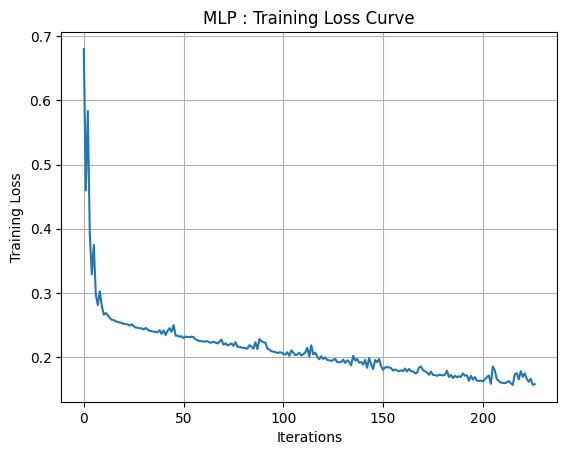

In [185]:
plot_training_loss( model_relu )


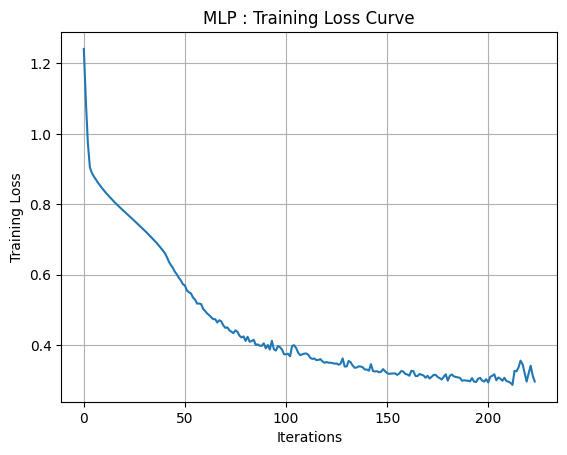

In [186]:
plot_training_loss( model_tanh )


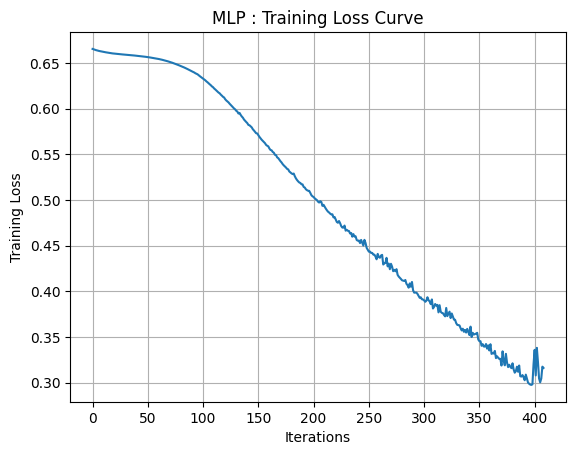

In [187]:
plot_training_loss( model_logistic )

In [188]:
#update_model_dict( "relu", acc_relu )
#update_model_dict( "tanh", acc_tanh )
#update_model_dict( "logistic", acc_logistic )

# make function for creating variants

In [189]:
model_dict = { "name" : [], "accuracy_score" : [] }

In [190]:
def update_model_dict( model_name, model_acc ) :
  model_dict["name"].append( model_name )
  model_dict["accuracy_score"].append( model_acc )

In [191]:
def model_pipeline( iter_value, activation_func, tuple_value ) :
  model = MLPClassifier( hidden_layer_sizes=tuple(tuple_value), max_iter=int(iter_value), activation = str(activation_func) )
  model.fit( X_train, y_train )
  pred = model.predict( X_test )
  acc = accuracy_score( y_true = y_test, y_pred = pred )
  update_model_dict( model_name = f"{activation_func}_{iter_value}", model_acc = acc )

In [192]:
def funnel_like_tuple( layers_num ) :
  layers_num = int( layers_num )

  result = [2]
  if( layers_num == 1 ) :
    return tuple(result)
  for i in range(1,layers_num) :
    result.append( 2*result[-1] )
    #print(result)
  result.reverse(  ) #modifies the original list
  result = tuple(result)
  return result

In [193]:
#print( funnel_like_tuple( 5 ) )

In [194]:
def create_tuple_list( variant_num ) :
  variant_num = int( variant_num )
  result = []
  for i in range(1,variant_num+1) :
    result.append( funnel_like_tuple( i ) )
  return result

In [195]:
LAYER_TUPLE = ( 16,8,4,2 )

In [196]:
iter_list = [100, 500, 1000, 2000]
activation_list = [ "relu", "tanh", "logistic" ]
tuple_list = create_tuple_list( 5 )

#4*3*5 = 60 variations

In [197]:
for activation_func in activation_list :
  for tuple_value in tuple_list :
    for iter_value in iter_list :
      model_pipeline( iter_value, activation_func, tuple_value )

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptr

# make comparison table

In [198]:
import pandas as pd

In [199]:
model_table = pd.DataFrame( model_dict )

In [200]:
model_table.head( len( model_table ) )

,name,accuracy_score
0,relu_100,0.622807
1,relu_500,0.622807
2,relu_1000,0.912281
3,relu_2000,0.947368
4,relu_100,0.622807
5,relu_500,0.964912
6,relu_1000,0.947368
7,relu_2000,0.956140
8,relu_100,0.938596
9,relu_500,0.622807


In [203]:
sorted_comparison = model_table.sort_values( by="accuracy_score", ascending=False )

In [204]:
sorted_comparison.head( 10 )

,name,accuracy_score
5,relu_500,0.964912
15,relu_2000,0.964912
12,relu_100,0.956140
7,relu_2000,0.956140
38,tanh_1000,0.956140
51,logistic_2000,0.956140
30,tanh_1000,0.956140
3,relu_2000,0.947368
32,tanh_100,0.947368
6,relu_1000,0.947368
